# UCS420: Cognitive Computing
## Assignment 10 ? Heart Health Information Assistant

**Student Name:** Lakshay Kapur  
**Roll Number:** 1024170060 (even)

This classroom assistant answers general heart-health questions from a small, source-linked knowledge base. Its corpus is hand-written for the assignment. It does not collect patient records or provide diagnosis, medication changes, or individual risk assessments.

**Google Colab:** Upload this notebook, run the cells in order, and run the final cell to chat. Colab includes the scientific Python libraries used below. In a fresh local Python environment, install nltk, pandas, matplotlib, and scikit-learn. NLTK downloads WordNet if it is missing.


### Q1. Develop a labelled corpus with at least 40 queries across five or more intent categories.
Use six intent labels and author training and held-out queries for each. Hold out the final two queries in every group before fitting TF-IDF or the classifier.


In [1]:
import pandas as pd

intent_queries = {
    "heart_basics": [
        "What is heart disease?",
        "Explain coronary artery disease.",
        "What are the major risk factors for heart disease?",
        "Why does family history affect heart health?",
        "What causes plaque to build up in the coronary arteries?",
        "How does smoking affect heart disease risk?",
        "What increases the risk of coronary artery disease?",
        "What role does tobacco play in cardiovascular risk?",
        "How is family history linked to coronary artery disease?",
        "Why are some people more likely to develop heart disease?",
    ],
    "blood_pressure": [
        "How do I measure blood pressure at home?",
        "What do the two blood pressure numbers mean?",
        "What is systolic and diastolic pressure?",
        "How should I position my arm for a blood pressure reading?",
        "What kind of blood pressure cuff should I use?",
        "How do I check my blood pressure correctly?",
        "Should I write down my blood pressure readings?",
        "How can I prepare for a blood pressure measurement?",
        "What does the top number on a blood pressure monitor represent?",
        "How do I select an upper arm cuff for checking blood pressure?",
    ],
    "cholesterol": [
        "What is LDL cholesterol?",
        "Can you explain HDL and LDL?",
        "What does a cholesterol test measure?",
        "What is a lipid panel?",
        "What are triglycerides on a cholesterol report?",
        "Why is LDL called bad cholesterol?",
        "How can high LDL affect my arteries?",
        "What is the difference between HDL and LDL cholesterol?",
        "What does a lipid profile tell a clinician?",
        "Why are LDL and triglycerides included on a test?",
    ],
    "heart_healthy_food": [
        "What foods are good for heart health?",
        "What is a heart healthy diet?",
        "How can I cut back on salt in my meals?",
        "What are examples of foods with fiber?",
        "What kinds of fats should I limit in a heart healthy diet?",
        "Does eating vegetables support heart health?",
        "How do whole grains fit into heart healthy eating?",
        "Why should I compare sodium on food labels?",
        "What can I eat for a heart healthy lunch?",
        "How much does reducing salt matter for heart healthy eating?",
    ],
    "physical_activity": [
        "How does exercise help my heart?",
        "Is brisk walking a moderate activity?",
        "What is a general exercise goal for adults?",
        "Can cycling count as aerobic exercise?",
        "How does physical activity support cardiovascular health?",
        "Can I build up my walking routine gradually?",
        "What are examples of moderate intensity exercise?",
        "How much weekly exercise is recommended for adults?",
        "Can a short brisk walk count as physical activity?",
        "Why is regular aerobic exercise useful?",
    ],
    "warning_signs": [
        "What are the warning signs of a heart attack?",
        "How can I recognize heart attack symptoms?",
        "What might a heart attack feel like?",
        "What symptoms can indicate a possible heart attack?",
        "Can a heart attack cause upper body discomfort?",
        "What does the American Heart Association list as common heart attack signs?",
        "Can breathlessness be a warning sign of a heart attack?",
        "What early signs should people learn about heart attacks?",
        "What clues might point to a heart attack?",
        "Is chest discomfort a known warning sign of a heart attack?",
    ],
}

def label_queries(query_groups, split):
    return pd.DataFrame(
        [(query, intent) for intent, queries in query_groups.items() for query in queries[split]],
        columns=["query", "intent"],
    )

train = label_queries(intent_queries, slice(None, -2))
test = label_queries(intent_queries, slice(-2, None))
assert len(train) + len(test) >= 40 and train["intent"].nunique() >= 5
assert set(train["query"]).isdisjoint(test["query"])
print(f"{len(train)} training queries and {len(test)} held-out queries.")
display(pd.concat([train["intent"].value_counts().rename("Train"),
                   test["intent"].value_counts().rename("Held out")], axis=1))


48 training queries and 12 held-out queries.


,Train,Held out
intent,,
heart_basics,8,2
blood_pressure,8,2
cholesterol,8,2
heart_healthy_food,8,2
physical_activity,8,2
warning_signs,8,2


### Q2. Create a hierarchical taxonomy with at least four major categories and two subcategories under each.


In [2]:
taxonomy = {
    "Understanding heart disease": ("Coronary artery disease", "Risk factors"),
    "Measuring heart health": ("Blood pressure", "Cholesterol"),
    "Prevention habits": ("Heart-healthy eating", "Physical activity"),
    "Recognizing and responding": ("Warning signs", "Emergency response"),
}

assert len(taxonomy) >= 4 and all(len(children) >= 2 for children in taxonomy.values())
for category, children in taxonomy.items():
    print(category)
    for child in children:
        print(f"  - {child}")


Understanding heart disease
  - Coronary artery disease
  - Risk factors
Measuring heart health
  - Blood pressure
  - Cholesterol
Prevention habits
  - Heart-healthy eating
  - Physical activity
Recognizing and responding
  - Warning signs
  - Emergency response


### Q3. Identify at least eight domain concepts and define at least ten relationships.
The triples below connect risk factors, measurements, prevention habits, and warning signs. Sources include the [CDC risk factors overview](https://www.cdc.gov/heart-disease/risk-factors/), [CDC cholesterol overview](https://www.cdc.gov/cholesterol/about/index.html), [CDC prevention guide](https://www.cdc.gov/heart-disease/prevention/), and [AHA warning signs](https://www.heart.org/en/health-topics/heart-attack/warning-signs-of-a-heart-attack).


In [3]:
relationships = [
    ("High blood pressure", "increases risk of", "Heart disease"),
    ("Smoking", "increases risk of", "Heart disease"),
    ("Family history", "can increase risk of", "Heart disease"),
    ("LDL cholesterol", "at high levels can contribute to", "Arterial plaque"),
    ("Arterial plaque", "can narrow", "Coronary arteries"),
    ("Cholesterol test", "measures", "LDL cholesterol"),
    ("Cholesterol test", "measures", "HDL cholesterol"),
    ("Physical activity", "can help lower", "High blood pressure"),
    ("Sodium reduction", "can help lower", "High blood pressure"),
    ("Heart attack", "can present with", "Chest discomfort"),
    ("Heart attack", "can present with", "Shortness of breath"),
]
concepts = {term for source, _, target in relationships for term in (source, target)}
assert len(concepts) >= 8 and len(relationships) >= 10
print(f"{len(concepts)} concepts and {len(relationships)} relationships")
display(pd.DataFrame(relationships, columns=["Subject", "Relationship", "Object"]))


14 concepts and 11 relationships


,Subject,Relationship,Object
0,High blood pressure,increases risk of,Heart disease
1,Smoking,increases risk of,Heart disease
2,Family history,can increase risk of,Heart disease
3,LDL cholesterol,at high levels can contribute to,Arterial plaque
4,Arterial plaque,can narrow,Coronary arteries
5,Cholesterol test,measures,LDL cholesterol
6,Cholesterol test,measures,HDL cholesterol
7,Physical activity,can help lower,High blood pressure
8,Sodium reduction,can help lower,High blood pressure
9,Heart attack,can present with,Chest discomfort


### Q4. Implement lowercase conversion, tokenization, stopword removal, and lemmatization.
Keep negation terms. Apply separate rules to the original query so emergency phrases are checked before text classification.


In [4]:
import re
import nltk
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

try:
    nltk.data.find("corpora/wordnet.zip")
except LookupError:
    nltk.download("wordnet", quiet=True, raise_on_error=True)

lemmatizer = WordNetLemmatizer()
stop_words = ENGLISH_STOP_WORDS - {"no", "nor", "not", "without"}

def preprocess(text):
    words = re.findall(r"[a-z]+", text.lower())
    return [lemmatizer.lemmatize(word) for word in words if word not in stop_words]

print(preprocess("Can physical activities help patients who do not exercise?"))


['physical', 'activity', 'help', 'patient', 'not', 'exercise']


### Q5. Extract TF-IDF features and train a Naive Bayes, logistic regression, or SVM classifier.
Use a single pipeline so the same preprocessing runs on training, evaluation, and live queries.


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

vectorizer = TfidfVectorizer(
    tokenizer=preprocess, token_pattern=None, lowercase=False, ngram_range=(1, 2)
)
classifier = LogisticRegression(C=12, max_iter=1000, random_state=42)
model = make_pipeline(vectorizer, classifier).fit(train["query"], train["intent"])
print(f"TF-IDF vocabulary: {len(vectorizer.vocabulary_)} terms")


TF-IDF vocabulary: 242 terms


### Q6. Evaluate accuracy, precision, recall, F1-score, and the confusion matrix.
The evaluation measures intent labeling on the 12 hand-written held-out examples. It does not measure medical accuracy or the reliability of emergency detection.


Held-out accuracy: 1.000

                    precision    recall  f1-score   support

    blood_pressure       1.00      1.00      1.00         2
       cholesterol       1.00      1.00      1.00         2
      heart_basics       1.00      1.00      1.00         2
heart_healthy_food       1.00      1.00      1.00         2
 physical_activity       1.00      1.00      1.00         2
     warning_signs       1.00      1.00      1.00         2

          accuracy                           1.00        12
         macro avg       1.00      1.00      1.00        12
      weighted avg       1.00      1.00      1.00        12

Held-out intent predictions:


,query,intent,predicted_intent
0,How is family history linked to coronary arter...,heart_basics,heart_basics
1,Why are some people more likely to develop hea...,heart_basics,heart_basics
2,What does the top number on a blood pressure m...,blood_pressure,blood_pressure
3,How do I select an upper arm cuff for checking...,blood_pressure,blood_pressure
4,What does a lipid profile tell a clinician?,cholesterol,cholesterol
5,Why are LDL and triglycerides included on a test?,cholesterol,cholesterol
6,What can I eat for a heart healthy lunch?,heart_healthy_food,heart_healthy_food
7,How much does reducing salt matter for heart h...,heart_healthy_food,heart_healthy_food
8,Can a short brisk walk count as physical activ...,physical_activity,physical_activity
9,Why is regular aerobic exercise useful?,physical_activity,physical_activity


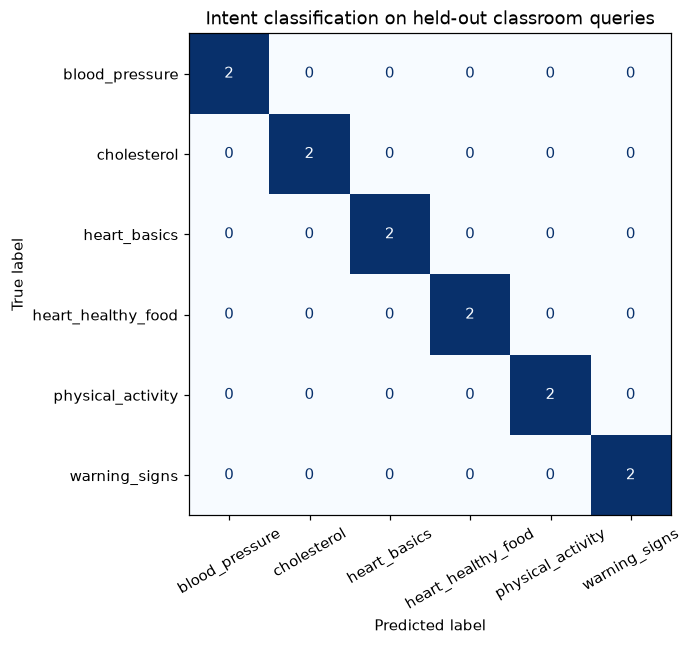

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report

predicted = model.predict(test["query"])
print(f"Held-out accuracy: {accuracy_score(test['intent'], predicted):.3f}\n")
print(classification_report(test["intent"], predicted, labels=classifier.classes_, zero_division=0))
print("Held-out intent predictions:")
display(test.assign(predicted_intent=predicted))

fig, ax = plt.subplots(figsize=(9, 6))
ConfusionMatrixDisplay.from_predictions(
    test["intent"], predicted, labels=classifier.classes_,
    xticks_rotation=30, cmap="Blues", colorbar=False, ax=ax,
)
ax.set_title("Intent classification on held-out classroom queries")
fig.tight_layout()
plt.show()


### Q7. Build a domain-specific knowledge base with information for every intent.
Each response is general education and links to the relevant source.


In [7]:
cdc_prevention = "https://www.cdc.gov/heart-disease/prevention/"
aha_warning_signs = "https://www.heart.org/en/health-topics/heart-attack/warning-signs-of-a-heart-attack"
india_112 = "https://www.mha.gov.in/emergency-response-support-system-erss"

knowledge_base = {
    "heart_basics": (
        "High blood pressure, high cholesterol, and smoking are major heart disease risk factors. "
        "Family history can also affect risk.",
        "https://www.cdc.gov/heart-disease/risk-factors/",
    ),
    "blood_pressure": (
        "For home monitoring, the American Heart Association recommends a validated upper-arm cuff. "
        "Sit quietly first and support your arm at heart level. Share readings with your clinician.",
        "https://www.heart.org/en/health-topics/high-blood-pressure/"
        "understanding-your-blood-pressure-readings/monitoring-your-blood-pressure-at-home",
    ),
    "cholesterol": (
        "A lipid panel typically reports LDL, HDL, and triglycerides. High LDL can promote plaque buildup "
        "in arteries. A clinician can interpret the results in the context of your overall risk.",
        "https://www.cdc.gov/cholesterol/about/index.html",
    ),
    "heart_healthy_food": (
        "Heart-healthy eating includes fruits, vegetables, and other fiber-rich foods. "
        "Limiting sodium can help lower blood pressure.",
        cdc_prevention,
    ),
    "physical_activity": (
        "For adults, a common public-health goal is about 150 minutes of moderate activity per week. "
        "Brisk walking and cycling are examples. Ask a clinician about activity appropriate to your health.",
        cdc_prevention,
    ),
    "warning_signs": (
        "Possible heart attack warning signs include chest discomfort, shortness of breath, and discomfort "
        "in the arm, jaw, or back. If these signs are happening now, call local emergency services "
        "(112 in India) immediately.",
        aha_warning_signs,
    ),
}

assert set(knowledge_base) == set(classifier.classes_)


### Q8. Implement at least five rules, including emergency escalation, low-confidence handling, and unsupported queries.
Rules take precedence in this order: emergency signs, empty query, requests for diagnosis or treatment, outside-domain terms or no matching vocabulary, and a weak or ambiguous classifier result. This classroom keyword screen can miss emergencies. The probability and margin thresholds are heuristics for the demo.


In [8]:
def contains(text, pattern):
    return re.search(pattern, text, re.IGNORECASE) is not None

critical = r"\b(unresponsive|not breathing|can(?:not|'t) breathe|passed out|collaps(?:e|ed|ing))\b"
symptoms = (
    r"\b(chest (?:pain|pressure|tightness|discomfort)|pain in (?:my|the|his|her) chest|"
    r"short(?:ness)? of breath|breathless(?:ness)?|heart attack)\b"
)
educational = r"^\s*(can|could|does|how|is|what|when|which|why)\b"
current_symptom = (
    r"\b(?:i(?:'m| am) (?:having|feeling)|i(?:'ve| have) (?:got )?|"
    r"i feel|having|feeling|right now|at the moment|just started|my chest|"
    r"(?:he|she|they|someone|my \w+) (?:has|have|reports?|is experiencing))\b"
)
treatment = r"\b(?:dose|dosage|prescri\w*|diagnos\w*|should i (?:take|stop|start)|adjust my)\b"
outside_domain = r"\b(?:eczema|rash|migraine|toothache|ear infection|sprained ankle|skin infection)\b"

def safety_rule(query):
    text = query.lower().replace("?", "'").strip()
    if contains(text, critical) or (
        contains(text, symptoms)
        and (contains(text, current_symptom) or not contains(text, educational))
    ):
        return "emergency", (
            "Call local emergency services now (112 in India). "
            "Do not wait for this assistant to assess the symptoms."
        ), india_112
    if not text:
        return "empty", "Enter a general question about heart health.", None
    if contains(text, treatment):
        return "clinical_request", "Ask a qualified clinician about diagnosis or medication decisions.", None
    if contains(text, outside_domain) or vectorizer.transform([text]).nnz == 0:
        return "unsupported", (
            "I cover general questions about heart disease, blood pressure, cholesterol, "
            "food, exercise, and warning signs."
        ), None
    return None


### Q9. Integrate preprocessing, classification, reasoning, and knowledge retrieval into one assistant.


In [9]:
def answer(query):
    matched_rule = safety_rule(query)
    if matched_rule is not None:
        return matched_rule

    scores = model.predict_proba([query])[0]
    best, second = scores.argsort()[-2:][::-1]
    if scores[best] < 0.30 or scores[best] - scores[second] < 0.10:
        return "low_confidence", "Please rephrase your question around one heart-health topic.", None

    intent = str(classifier.classes_[best])
    response, source = knowledge_base[intent]
    return intent, response, source


### Test the assistant.
Try each intent, a differently worded question, an unsupported healthcare question, a low-confidence question, and an emergency-related question. Include checks for empty and medication questions.


In [10]:
demo_cases = [
    ("What raises the risk of coronary artery disease?", "heart_basics"),
    ("How do I measure my blood pressure at home?", "blood_pressure"),
    ("What does an LDL cholesterol test measure?", "cholesterol"),
    ("What foods fit a heart healthy diet?", "heart_healthy_food"),
    ("How can brisk walking count as exercise?", "physical_activity"),
    ("What are the warning signs of a heart attack?", "warning_signs"),
    ("Can cycling be part of my aerobic exercise routine?", "physical_activity"),
    ("What helps eczema?", "unsupported"),
    ("What do cholesterol and exercise have in common?", "low_confidence"),
    ("I have chest pressure and shortness of breath right now.", "emergency"),
    ("Can you help? My dad has chest pain.", "emergency"),
    ("", "empty"),
    ("Should I stop my blood pressure medication?", "clinical_request"),
]

for query, expected in demo_cases:
    route, response, source = answer(query)
    print(f"\nQuestion: {query or '[empty]'}")
    print(f"Route: {route}\n{response}")
    if source:
        print(f"Source: {source}")
    assert route == expected, f"Expected {expected}, got {route} for {query!r}"



Question: What raises the risk of coronary artery disease?
Route: heart_basics
High blood pressure, high cholesterol, and smoking are major heart disease risk factors. Family history can also affect risk.
Source: https://www.cdc.gov/heart-disease/risk-factors/

Question: How do I measure my blood pressure at home?
Route: blood_pressure
For home monitoring, the American Heart Association recommends a validated upper-arm cuff. Sit quietly first and support your arm at heart level. Share readings with your clinician.
Source: https://www.heart.org/en/health-topics/high-blood-pressure/understanding-your-blood-pressure-readings/monitoring-your-blood-pressure-at-home

Question: What does an LDL cholesterol test measure?
Route: cholesterol
A lipid panel typically reports LDL, HDL, and triglycerides. High LDL can promote plaque buildup in arteries. A clinician can interpret the results in the context of your overall risk.
Source: https://www.cdc.gov/cholesterol/about/index.html

Question: What

### Q10. Provide a Google Colab interface that accepts multiple queries and displays appropriate responses.
Run the next cell in Colab, enter questions one at a time, and type **quit** to stop. Queries are processed within the notebook session.


In [ ]:
def chat():
    print("Heart Health Information Assistant | Type 'quit' to exit.")
    while True:
        try:
            query = input("\nYour question: ").strip()
        except (EOFError, KeyboardInterrupt):
            break
        if query.lower() in {"quit", "exit"}:
            break
        _, response, source = answer(query)
        print(response)
        if source:
            print(f"Source: {source}")
    print("Session ended.")

chat()
